# 00 — Replicate Figure 15: inference-time steering predicts subliminal transfer

Re-derives **Figure 15 (Appendix G)** of *Subliminal Learning Is Steering Vector Distillation*
(Blank et al., 2026, [arXiv:2606.00995](https://arxiv.org/abs/2606.00995)) from the authors' released results on
Hugging Face (`agu18dec/steering_vector_distillation`). No GPU needed.

For each of 16 animals:
- **x: clean inference-time steering rate.** The highest rate at which steering the reference model with `v_teacher`
  makes it name the animal, among layer/α settings where it names the animal on fewer than 10% of
  "least favorite animal" questions (the paper's specificity check, Appendix G).
- **y: student rate.** How often the student trained by subliminal learning names the animal.

The paper prints an **AUC** on each panel: the probability that a randomly chosen subliminally-learned (SL) animal has
a higher steering rate than a randomly chosen non-SL animal (OLMo 0.91, Llama 1.00).

Note: this re-analyzes the authors' released numbers; it doesn't rerun their models.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from huggingface_hub import hf_hub_download

REPO = "agu18dec/steering_vector_distillation"
get = lambda path: hf_hub_download(REPO, path, repo_type="dataset")

/Users/tets/Documents/GitHub/AI Safety/bluedot/steering-vector-distillation/.venv-analysis/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load released results

- **OLMo-3-7B-Instruct:** student rates from `vectors/zoo/olmo/best_steering.json`; clean steering peaks from each
  animal's `vectors/zoo/olmo/sweeps/<animal>/sweep_clean.json` (`clean_peak_pos`). The steering rates in
  `best_steering.json` are unconstrained peaks, which the paper does not plot.
- **Llama-3.1-8B-Instruct:** `vectors/zoo/llama/results_clean.csv`, which already holds the clean peaks.

In [2]:
best = json.load(open(get("vectors/zoo/olmo/best_steering.json")))
olmo = pd.DataFrame([
    {"animal": a,
     "steering_rate": json.load(open(get(f"vectors/zoo/olmo/sweeps/{a}/sweep_clean.json")))["clean_peak_pos"],
     "student_rate": d["sl_rate"]}
    for a, d in best.items()
])

llama = (pd.read_csv(get("vectors/zoo/llama/results_clean.csv"))
           .rename(columns={"peak_pos_rate": "steering_rate", "sl_rate": "student_rate"})
           [["animal", "steering_rate", "student_rate"]])

models = {"OLMo-3-7B-Instruct": olmo, "Llama-3.1-8B-Instruct": llama}
for name, df in models.items():
    print(name)
    display(df.sort_values("steering_rate", ascending=False).round(3).reset_index(drop=True))

OLMo-3-7B-Instruct


,animal,steering_rate,student_rate
0,elephant,0.625,0.086
1,dolphin,0.611,0.154
2,wolf,0.584,0.314
3,whale,0.492,0.042
4,tiger,0.486,0.149
5,lion,0.312,0.026
6,falcon,0.292,0.015
7,hawk,0.249,0.046
8,dog,0.147,0.217
9,cat,0.144,0.012


Llama-3.1-8B-Instruct


,animal,steering_rate,student_rate
0,octopus,0.689,0.674
1,dolphin,0.509,0.137
2,whale,0.328,0.002
3,wolf,0.281,0.006
4,cat,0.202,0.000
5,tiger,0.160,0.000
6,pangolin,0.129,0.001
7,lion,0.116,0.003
8,dog,0.085,0.001
9,elephant,0.059,0.005


## AUC: does steering rate separate SL from non-SL animals?

The paper doesn't state its cutoff for counting an animal as subliminally learned. A student rate above **5%**
reproduces both printed AUCs exactly; the sweep below shows how the AUC depends on that choice.

In [3]:
SL_THRESHOLD = 0.05  # inferred: reproduces the paper's printed AUCs
PAPER_AUC = {"OLMo-3-7B-Instruct": 0.91, "Llama-3.1-8B-Instruct": 1.00}

def auc(df, thr=SL_THRESHOLD):
    pos = df.loc[df.student_rate > thr, "steering_rate"].to_numpy()
    neg = df.loc[df.student_rate <= thr, "steering_rate"].to_numpy()
    if len(pos) == 0 or len(neg) == 0:
        return np.nan
    return ((pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])).mean()

print(pd.DataFrame([{"model": m, "paper AUC": PAPER_AUC[m], "our AUC": round(auc(df), 3),
                     "n SL animals": int((df.student_rate > SL_THRESHOLD).sum())} for m, df in models.items()]).to_string(index=False))

print("\nSensitivity to the SL cutoff:")
thresholds = [0.01, 0.02, 0.03, 0.04, 0.05, 0.1]
print(pd.DataFrame({m: [round(auc(df, t), 3) for t in thresholds] for m, df in models.items()},
                   index=[f"student_rate > {t}" for t in thresholds]).to_string())

                model  paper AUC  our AUC  n SL animals
   OLMo-3-7B-Instruct       0.91    0.909             5
Llama-3.1-8B-Instruct       1.00    1.000             2

Sensitivity to the SL cutoff:
                     OLMo-3-7B-Instruct  Llama-3.1-8B-Instruct
student_rate > 0.01               1.000                    1.0
student_rate > 0.02               0.900                    1.0
student_rate > 0.03               0.841                    1.0
student_rate > 0.04               0.937                    1.0
student_rate > 0.05               0.909                    1.0
student_rate > 0.1                0.812                    1.0


## Correlation (baseline for a geometry-only predictor)

The paper reports no correlation coefficient. Spearman ρ (rank agreement) is the baseline a predictor computed from
`v_teacher` alone has to match or beat. With 16 animals per model, the bootstrap intervals are wide.

In [4]:
def boot_spearman(x, y, n=10_000, seed=0):
    rng = np.random.default_rng(seed); x, y = np.asarray(x), np.asarray(y); vals = []
    for _ in range(n):
        i = rng.integers(0, len(x), len(x))
        if np.ptp(x[i]) > 0 and np.ptp(y[i]) > 0:
            vals.append(stats.spearmanr(x[i], y[i]).statistic)
    return np.percentile(vals, [2.5, 97.5])

rows = []
for m, df in models.items():
    lo, hi = boot_spearman(df.steering_rate, df.student_rate)
    rows.append({"model": m, "n": len(df),
                 "spearman": stats.spearmanr(df.steering_rate, df.student_rate).statistic,
                 "spearman_95CI": f"[{lo:.2f}, {hi:.2f}]",
                 "pearson": stats.pearsonr(df.steering_rate, df.student_rate).statistic})
pd.DataFrame(rows).round(3)

,model,n,spearman,spearman_95CI,pearson
0,OLMo-3-7B-Instruct,16,0.782,"[0.43, 0.92]",0.603
1,Llama-3.1-8B-Instruct,16,0.768,"[0.38, 0.93]",0.797


## Figure 15, re-derived

In [5]:
from matplotlib.transforms import Bbox

def place_labels(ax, xs, ys, names, colors, fontsize=8, pad=2, step=4, max_steps=200):
    """Label points like the paper's Figure 15: start each label beside its point; if it overlaps another
    label or a marker, push it upward until clear and draw a thin grey leader line back to the point."""
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    to_px = ax.transData.transform
    to_data = ax.transData.inverted().transform
    pts = to_px(np.column_stack([xs, ys]))
    marker = 6  # half-width of a marker box in pixels
    occupied = [Bbox.from_extents(px - marker, py - marker, px + marker, py + marker) for px, py in pts]
    axbox = ax.get_window_extent(r)
    for i in np.lexsort((pts[:, 0], pts[:, 1])):  # bottom-to-top, then left-to-right
        px, py = pts[i]
        dark = tuple(0.6 * c for c in colors[i][:3])  # darker text so light marker colours stay readable
        t = ax.text(0, 0, names[i], fontsize=fontsize, color=dark, zorder=4,
                    bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none", alpha=0.85))
        w = t.get_window_extent(r).width + 2 * pad
        h = t.get_window_extent(r).height + 2 * pad
        x0, y0 = px + marker, py + 1
        for k in range(max_steps):
            box = Bbox.from_bounds(x0, y0 + k * step, w, h)
            if box.x1 > axbox.x1:  # keep labels inside the axes
                box = Bbox.from_bounds(px - marker - w, y0 + k * step, w, h)
            if not any(box.overlaps(o) for o in occupied):
                break
        occupied.append(box)
        tx, ty = to_data((box.x0 + pad, box.y0 + pad))
        t.set_position((tx, ty))
        if k > 2:  # moved away from its point: connect with a leader line
            lx, ly = to_data((box.x0 + pad if box.x0 > px else box.x1 - pad, box.y0 + pad))
            ax.plot([xs[i], lx], [ys[i], ly], color="0.6", lw=0.6, zorder=1)

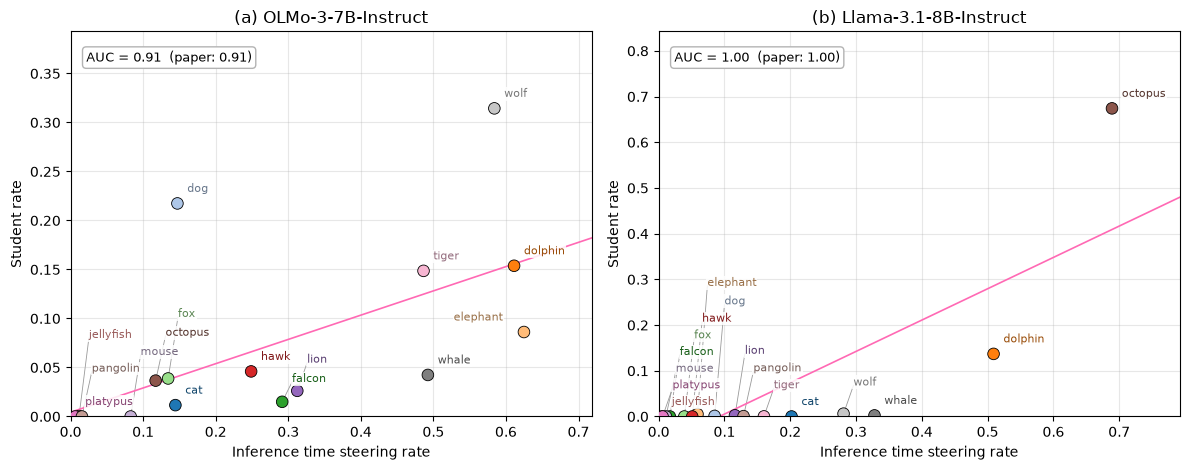

In [6]:
animals = sorted(olmo.animal)
cmap = plt.get_cmap("tab20")
COLORS = {a: cmap(i) for i, a in enumerate(animals)}  # same colour per animal in both panels

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (label, (name, df)) in zip(axes, zip("ab", models.items())):
    colors = [COLORS[a] for a in df.animal]
    ax.scatter(df.steering_rate, df.student_rate, s=70, c=colors, edgecolor="k", linewidth=0.6, zorder=3)
    slope, intercept = np.polyfit(df.steering_rate, df.student_rate, 1)
    xs = np.linspace(0, df.steering_rate.max() * 1.15, 50)
    ax.plot(xs, slope * xs + intercept, color="hotpink", lw=1.2, zorder=2)
    ax.text(0.03, 0.95, f"AUC = {auc(df):.2f}  (paper: {PAPER_AUC[name]:.2f})", transform=ax.transAxes,
            va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    ax.set(title=f"({label}) {name}", xlabel="Inference time steering rate", ylabel="Student rate",
           xlim=(0, df.steering_rate.max() * 1.15), ylim=(0, df.student_rate.max() * 1.25))
    ax.grid(alpha=0.3)
    place_labels(ax, df.steering_rate.to_numpy(), df.student_rate.to_numpy(), list(df.animal), colors)
plt.tight_layout()
plt.savefig("figure15_replication.png", dpi=150)
plt.show()

## Notes

- Points, fitted lines, and AUCs match Figure 15 (paper p. 23): e.g. OLMo wolf (0.58, 0.31), dolphin (0.61, 0.15),
  dog (0.15, 0.22); Llama octopus (0.69, 0.67), dolphin (0.51, 0.14).
- The SL cutoff (student rate > 5%) is inferred, not stated in the paper.
- **Llama is very skewed:** only octopus and dolphin clearly transfer. OLMo has a better spread and is the better test set.
- Next: replace `steering_rate` with scores computed from `v_teacher` alone and compare them to this baseline.